# 딥러닝과 모델 저장

독창적 가상 데이터와 자체 연습 문항입니다. 제공 샘플의 흐름을 참고했으며 원문 복제가 아닙니다.

14문항 · 파트 연습 · 힌트 사용 가능

CSV 두 개와 노트북을 같은 폴더에 두세요. 커널 재시작 → 전체 실행 → 저장한 뒤 사이트에 제출하세요. 각 답안 다음 검증 셀은 실행 결과를 검사합니다. 검증 셀을 바꾸면 점수 신뢰도가 사라집니다. 공식 점수 예측이 아닌 자체 연습 점수입니다.

데이터: ticket_id 식별번호, created_at 접수일시, issue_type 문의유형, contact_channel 채널, membership_tier 등급, tenure_months 가입개월, monthly_spend 월금액(원), previous_tickets 과거 문의 수, wait_minutes 대기분, past_satisfaction_score 과거만족도(1~5), escalated 이관여부(0/1), resolution_hours 해결시간(시간). resolution_hours는 분류 입력에서 제외합니다.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score, confusion_matrix, mean_absolute_error
SET_ID='part-dl'
DATA_FILE="practice.csv"
MEMBERS_FILE="members.csv"
MODEL_FILE="best_part-dl.keras"

from pathlib import Path
import json as _json
from IPython.display import display as _display
_raw = pd.read_csv(DATA_FILE)
_grade_results = []
def _filled(d):
    x=d.copy()
    cols=['wait_minutes','past_satisfaction_score','monthly_spend']
    x[cols]=x[cols].fillna(x[cols].median())
    x['contact_channel']=x.contact_channel.fillna(x.contact_channel.mode().iloc[0])
    return x
def _plot_ok(fig,h,k1,k2,title,ylabel,labels=None):
    a=fig.axes[0]
    ls=a.get_lines()
    labels=labels or [k1,k2]
    return (len(ls)==2 and a.get_title()==title and a.get_xlabel()=='Epoch' and a.get_ylabel()==ylabel
      and np.allclose(ls[0].get_ydata(),h.history[k1]) and np.allclose(ls[1].get_ydata(),h.history[k2])
      and a.get_legend() is not None and [t.get_text() for t in a.get_legend().get_texts()]==labels)
def _grade_q(number,checks):
    items=[]
    for label,expr in checks:
        try:
            ok=bool(eval(expr,globals()))
            items.append({'label':label,'passed':ok,'detail':'검사 통과' if ok else '실행 결과가 지시와 다릅니다. 변수명·조건·파라미터를 확인하세요.'})
        except Exception as e:
            items.append({'label':label,'passed':False,'detail':type(e).__name__+': '+str(e)[:180]})
    report={'schema':'aice-lab-v1','setId':SET_ID,'question':number,'checks':items}
    _grade_results.append(report)
    _display({'application/json':report},raw=True)
data=pd.read_csv(DATA_FILE)
clean = data.drop_duplicates().copy()
clean = clean.loc[clean['wait_minutes'].isna() | (clean['wait_minutes'] < 300)].reset_index(drop=True)
num = ['wait_minutes','past_satisfaction_score','monthly_spend']
clean[num] = clean[num].fillna(clean[num].median())
clean['contact_channel'] = clean['contact_channel'].fillna(clean['contact_channel'].mode().iloc[0])
preset = pd.get_dummies(clean.drop(columns=['ticket_id','created_at','resolution_hours']), columns=['issue_type','contact_channel','membership_tier'], dtype=int)
X = preset.drop(columns='escalated')
y = preset['escalated']
X_train, X_valid, y_train, y_valid = train_test_split(X,y,test_size=0.3,random_state=7,stratify=y)
ss = StandardScaler()
X_train_scaled = ss.fit_transform(X_train)
X_valid_scaled = ss.transform(X_valid)
import tensorflow as tf
from tensorflow.keras.models import Sequential,load_model
from tensorflow.keras.layers import Input,Dense,Dropout
from tensorflow.keras.callbacks import EarlyStopping,ModelCheckpoint
tf.keras.utils.set_random_seed(7)


## 1. 출력층 선택 (7점)

Dense(1,activation="sigmoid")를 output_layer에 생성하세요.

In [35]:
# 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.layers import Dense

output_layer = Dense(1, activation="sigmoid")


In [36]:
_grade_q(1, [['출력 노드와 함수', 'output_layer.units==1 and output_layer.activation.__name__=="sigmoid"']])

## 2. 모델 구조 (7점)

model을 Input(특성 수) → Dense32 relu → Dropout0.2 → Dense16 relu → Dense1 sigmoid로 구성하세요.

In [37]:
# 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dropout

model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    output_layer
])

In [38]:
_grade_q(2, [['층 구성', '[type(l).__name__ for l in model.layers]==["Dense","Dropout","Dense","Dense"]'], ['Dense 크기와 활성화', '[(l.units,l.activation.__name__) for l in model.layers if hasattr(l,"units")]==[(32,"relu"),(16,"relu"),(1,"sigmoid")]'], ['Dropout', 'np.isclose(model.layers[1].rate,.2)']])

## 3. 컴파일 (7점)

adam, binary_crossentropy, accuracy로 model을 컴파일하세요.

In [39]:
# 여기에 답안코드를 작성하고 실행하세요.
model.compile(
    optimizer = "adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [40]:
_grade_q(3, [['손실과 옵티마이저', 'model.loss=="binary_crossentropy" and type(model.optimizer).__name__=="Adam"']])

## 4. EarlyStopping (7점)

estop에 val_loss, patience=5, 최적 가중치 복원=True로 설정하세요.

In [41]:
# 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

estop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [42]:
_grade_q(4, [['조기종료 설정', 'estop.monitor=="val_loss" and estop.patience==5 and estop.restore_best_weights']])

## 5. ModelCheckpoint (7점)

checkpoint에 MODEL_FILE 경로, val_loss, save_best_only=True로 설정하세요.

In [43]:
# 여기에 답안코드를 작성하고 실행하세요.
checkpoint = ModelCheckpoint(
    filepath=MODEL_FILE,
    monitor="val_loss",
    save_best_only=True
)

In [44]:
_grade_q(5, [['체크포인트 설정', 'str(checkpoint.filepath)==MODEL_FILE and checkpoint.monitor=="val_loss" and checkpoint.save_best_only']])

## 6. 검증 포함 학습 (7점)

훈련 scaled 데이터로 최대30 epoch, batch_size32, validation_data=(X_valid_scaled,y_valid), 콜백 두 개로 학습하고 history에 저장하세요.

In [45]:
# 여기에 답안코드를 작성하고 실행하세요.
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_valid_scaled, y_valid),
    callbacks=[estop, checkpoint]
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.5673 - loss: 0.6858 - val_accuracy: 0.6927 - val_loss: 0.6499
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7019 - loss: 0.6158 - val_accuracy: 0.7821 - val_loss: 0.5857
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7740 - loss: 0.5609 - val_accuracy: 0.7933 - val_loss: 0.5526
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7933 - loss: 0.5340 - val_accuracy: 0.7933 - val_loss: 0.5336
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7957 - loss: 0.5134 - val_accuracy: 0.7933 - val_loss: 0.5216
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7957 - loss: 0.5119 - val_accuracy: 0.7933 - val_loss: 0.5121
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7909 - loss: 0.4891 - val_accuracy: 0.7933 - val_loss: 0.5038
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8053 - loss: 0.4740 - val_accuracy: 0.7933 - val_loss

In [46]:
_grade_q(6, [['훈련과 검증 기록', '{"loss","val_loss","accuracy","val_accuracy"}.issubset(history.history) and 1<=len(history.epoch)<=30'], ['학습 epoch 설정', 'history.params["epochs"]==30'], ['최적 모델 파일 존재', 'Path(MODEL_FILE).is_file() and Path(MODEL_FILE).stat().st_size>100']])

## 7. 저장 모델 불러오기 (7점)

MODEL_FILE에서 모델을 불러와 best_model에 저장하세요.

In [47]:
# 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.models import load_model

best_model = load_model(MODEL_FILE)


In [48]:
_grade_q(7, [['독립 모델 객체', 'best_model is not model and best_model.input_shape==model.input_shape'], ['파일 모델 가중치 일치', 'all(np.allclose(a,b) for a,b in zip(best_model.get_weights(),load_model(MODEL_FILE).get_weights()))']])

## 8. evaluate (7점)

best_model로 검증 데이터를 평가하고 dl_loss, dl_acc에 저장하세요.

In [49]:
# 여기에 답안코드를 작성하고 실행하세요.
dl_loss, dl_acc = best_model.evaluate(X_valid_scaled, y_valid, verbose=0)

In [50]:
_grade_q(8, [['실제 평가값', 'np.allclose([dl_loss,dl_acc],best_model.evaluate(X_valid_scaled,y_valid,verbose=0),rtol=1e-5)']])

## 9. 확률과 ravel (7점)

best_model의 검증 확률을 1차원 dl_proba에 저장하세요.

In [51]:
# 여기에 답안코드를 작성하고 실행하세요.
dl_proba = best_model.predict(X_valid_scaled)[:,0]
dl_proba

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


array([0.10303782, 0.33675012, 0.1886278 , 0.16592528, 0.02756569,
       0.06440698, 0.31921387, 0.15543164, 0.04148376, 0.14100727,
       0.21871749, 0.25153294, 0.38894564, 0.33080336, 0.5499235 ,
       0.15396006, 0.27528426, 0.18853267, 0.24674653, 0.03428564,
       0.18365577, 0.28336114, 0.5910064 , 0.04162373, 0.02159212,
       0.20570537, 0.4199914 , 0.16155694, 0.11086168, 0.14976895,
       0.19330159, 0.05827964, 0.02788057, 0.07302997, 0.17335172,
       0.36423135, 0.76330256, 0.08335341, 0.05094621, 0.38798228,
       0.4308893 , 0.10101239, 0.26004282, 0.07007608, 0.24112251,
       0.14940518, 0.19235873, 0.29117864, 0.19617102, 0.02374261,
       0.18480998, 0.34115598, 0.03496053, 0.04535646, 0.64276594,
       0.01274337, 0.04492357, 0.18511242, 0.14637654, 0.03456772,
       0.06895432, 0.21802756, 0.13548337, 0.07940053, 0.25322413,
       0.02911489, 0.31154045, 0.16636278, 0.04928513, 0.1420466 ,
       0.0320638 , 0.61037016, 0.11746893, 0.0934276 , 0.12114

In [52]:
_grade_q(9, [['1차원 확률', 'np.asarray(dl_proba).shape==(len(y_valid),) and np.allclose(dl_proba,best_model.predict(X_valid_scaled,verbose=0).ravel())']])

## 10. 기준값 적용 (7점)

dl_proba에 0.5 기준을 적용한 정수형 dl_pred를 만드세요.

In [53]:
# 여기에 답안코드를 작성하고 실행하세요.
dl_pred = (dl_proba>=0.5).astype(int)

In [54]:
_grade_q(10, [['클래스 변환', 'np.array_equal(dl_pred,(dl_proba>=.5).astype(int)) and np.issubdtype(np.asarray(dl_pred).dtype,np.integer)']])

## 11. ROC-AUC (7점)

실제 정답과 dl_proba로 dl_auc를 계산하세요.

In [55]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.metrics import roc_auc_score

dl_auc = roc_auc_score(y_valid, dl_proba)

In [56]:
_grade_q(11, [['확률 기반 AUC', 'np.isclose(dl_auc,roc_auc_score(y_valid,dl_proba))']])

## 12. 혼동행렬 (7점)

실제 정답과 dl_pred로 dl_cm을 만드세요.

In [57]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.metrics import confusion_matrix

dl_cm = confusion_matrix(y_valid, dl_pred)

In [58]:
_grade_q(12, [['혼동행렬', 'np.array_equal(dl_cm,confusion_matrix(y_valid,dl_pred))']])

## 13. 손실 그래프 (7점)

fig_loss에 loss와 val_loss를 함께 그리세요. 범례 loss,val_loss, 제목 Model Loss, 축 Epoch/Loss.

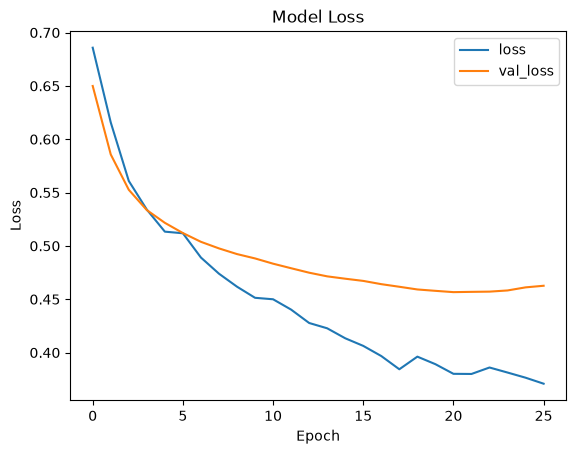

In [59]:
# 여기에 답안코드를 작성하고 실행하세요.
fig_loss = plt.figure()
plt.plot(history.history["loss"], label="loss")
plt.plot(history.history["val_loss"], label="val_loss")

plt.legend()
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [60]:
_grade_q(13, [['손실 곡선과 라벨', '_plot_ok(fig_loss,history,"loss","val_loss","Model Loss","Loss")']])

## 14. 정확도 그래프 (9점)

fig_acc에 accuracy와 val_accuracy를 함께 그리세요. 범례 acc,val_acc, 제목 Model Accuracy, 축 Epoch/Accuracy.

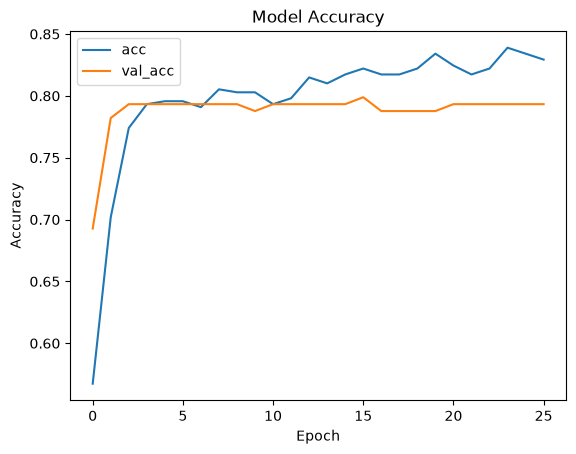

In [61]:
# 여기에 답안코드를 작성하고 실행하세요.
fig_acc = plt.figure()
plt.plot(history.history["accuracy"], label="acc")
plt.plot(history.history["val_accuracy"], label="val_acc")

plt.legend()
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

In [62]:
_grade_q(14, [['정확도 곡선과 라벨', '_plot_ok(fig_acc,history,"accuracy","val_accuracy","Model Accuracy","Accuracy",["acc","val_acc"])']])

## 제출
검증 결과를 포함한 상태로 저장하세요. VS Code에서 실행이 중단되면 오류를 고친 뒤 다시 전체 실행하세요. 설치가 필요하면 사이트의 환경 설정 안내를 확인하세요.